In [1]:
import os
import random
import numpy as np
import torch

from datasets import load_dataset
from torch.utils.data import DataLoader

from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    DataCollatorWithPadding,
    get_linear_schedule_with_warmup
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

from tqdm.auto import tqdm

In [2]:
if torch.cuda.is_available():
    DEVICE = torch.device('cuda')
elif torch.backends.mps.is_available():
    DEVICE = torch.device('mps')
elif torch.xpu.is_available():
    DEVICE = torch.device('xpu')
else:
    DEVICE = torch.device('cpu')

print(DEVICE)

cuda


In [3]:
SEED = 2026

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [4]:
MODEL_NAME = 'monologg/koelectra-base-v3-discriminator'

MAX_LENGTH = 128
BATCH_SIZE = 16
EPOCHS = 3
LEARNING_RATE = 1e-5

In [5]:
dataset = load_dataset("Blpeng/nsmc")

train_df = dataset['train'].to_pandas()
test_df = dataset['test'].to_pandas()

train_df = train_df[
    ['document', 'label']
]

test_df = test_df[
    ['document', 'label']
]

train_df.to_csv(
    "nsmc_train.csv",
    index=False,
    encoding='utf-8-sig'
)

test_df.to_csv(
    'nsmc_test.csv',
    index=False,
    encoding='utf-8-sig'
)

Repo card metadata block was not found. Setting CardData to empty.


In [6]:
dataset = load_dataset(
    'csv',
    data_files={
        'train': 'nsmc_train.csv',
        'test': 'nsmc_test.csv'
    }
)

print(dataset)

Generating train split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['document', 'label'],
        num_rows: 150000
    })
    test: Dataset({
        features: ['document', 'label'],
        num_rows: 50000
    })
})


In [7]:
def remove_empty(example):

    text = example['document']

    return (text is not None and str(text).strip() != '')

dataset = dataset.filter(remove_empty)

print(dataset)

Filter:   0%|          | 0/150000 [00:00<?, ? examples/s]

Filter:   0%|          | 0/50000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['document', 'label'],
        num_rows: 149995
    })
    test: Dataset({
        features: ['document', 'label'],
        num_rows: 49997
    })
})


In [8]:
train_valid = dataset['train'].train_test_split(
    test_size = 0.1,
    seed = SEED
)

train_dataset = train_valid['train']
valid_dataset = train_valid['test']
test_dataset = dataset['test']

print('Train:', len(train_dataset))
print('Validation:', len(valid_dataset))
print('Test:', len(test_dataset))

Train: 134995
Validation: 15000
Test: 49997


In [9]:
QUICK_MODE = False

if QUICK_MODE:

    train_dataset = (train_dataset.shuffle(seed=SEED).select(range(min(10000, len(train_dataset)))))
    valid_dataset = (valid_dataset.shuffle(seed=SEED).select(range(min(2000, len(valid_dataset)))))
    test_dataset = (test_dataset.shuffle(seed=SEED).select(range(min(5000, len(test_dataset)))))

print('Train:', len(train_dataset))
print('Validation:', len(valid_dataset))
print('Test:', len(test_dataset))

Train: 134995
Validation: 15000
Test: 49997


In [10]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

print(tokenizer)

BertTokenizer(name_or_path='monologg/koelectra-base-v3-discriminator', vocab_size=35000, model_max_length=512, padding_side='right', truncation_side='right', special_tokens={'unk_token': '[UNK]', 'sep_token': '[SEP]', 'pad_token': '[PAD]', 'cls_token': '[CLS]', 'mask_token': '[MASK]'}, added_tokens_decoder={
	0: AddedToken("[PAD]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	1: AddedToken("[UNK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	2: AddedToken("[CLS]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	3: AddedToken("[SEP]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
	4: AddedToken("[MASK]", rstrip=False, lstrip=False, single_word=False, normalized=False, special=True),
})


In [11]:
text = '배우들의 연기가 정말 좋았고 영화도 재미있었다.'

tokens = tokenizer.tokenize(text)

print(tokens)

['배우', '##들의', '연기', '##가', '정말', '좋', '##았', '##고', '영화', '##도', '재미있', '##었', '##다', '.']


In [12]:
def tokenize_function(examples):

    return tokenizer(
        examples['document'],
        truncation=True,
        max_length=MAX_LENGTH
    )

In [13]:
train_dataset = train_dataset.map(tokenize_function, batched=True, remove_columns=['document'])
valid_dataset = valid_dataset.map(tokenize_function, batched=True, remove_columns=['document'])
test_dataset = test_dataset.map(tokenize_function, batched=True, remove_columns=['document'])

Map:   0%|          | 0/134995 [00:00<?, ? examples/s]

Map:   0%|          | 0/15000 [00:00<?, ? examples/s]

Map:   0%|          | 0/49997 [00:00<?, ? examples/s]

In [14]:
train_dataset = train_dataset.rename_column('label', 'labels')
valid_dataset = valid_dataset.rename_column('label', 'labels')
test_dataset = test_dataset.rename_column('label', 'labels')

print(train_dataset[0])

{'labels': 0, 'input_ids': [2, 7394, 8675, 6394, 18474, 4150, 4142, 4007, 6428, 6913, 4216, 4569, 16949, 4279, 4219, 13215, 4065, 4034, 2181, 23200, 6234, 4073, 18, 18, 18, 26759, 4474, 6702, 14278, 4034, 3093, 4679, 4172, 3], 'token_type_ids': [0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], 'attention_mask': [1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1]}


In [15]:
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, collate_fn=data_collator)
valid_loader = DataLoader(valid_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=data_collator)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, collate_fn=data_collator)

In [16]:
id2label = {
    0: "NEGATIVE",
    1: "POSITIVE"
}

label2id = {
    "NEGATIVE": 0,
    "POSITIVE": 1
}

In [17]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME,
    num_labels=2,
    id2label=id2label,
    label2id=label2id
)

model = model.to(DEVICE)

print(model.__class__.__name__)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] ElectraForSequenceClassification LOAD REPORT from: monologg/koelectra-base-v3-discriminator
Key                                               | Status     | 
--------------------------------------------------+------------+-
discriminator_predictions.dense_prediction.weight | UNEXPECTED | 
discriminator_predictions.dense.weight            | UNEXPECTED | 
discriminator_predictions.dense.bias              | UNEXPECTED | 
discriminator_predictions.dense_prediction.bias   | UNEXPECTED | 
classifier.dense.weight                           | MISSING    | 
classifier.out_proj.bias                          | MISSING    | 
classifier.out_proj.weight                        | MISSING    | 
classifier.dense.bias                             | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your do

ElectraForSequenceClassification


In [18]:
optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=0.01)

total_steps = (len(train_loader) * EPOCHS)
scheduler = get_linear_schedule_with_warmup(optimizer, num_warmup_steps=int(total_steps * 0.1), num_training_steps=total_steps)

In [19]:
def calculate_metrics(labels, predictions):

    accuracy = accuracy_score(labels, predictions)
    precision = precision_score(labels, predictions, zero_division=0)
    recall = recall_score(labels, predictions, zero_division=0)
    f1 = f1_score(labels, predictions, zero_division=0)

    return {
        "accuracy": accuracy,
        "precision": precision,
        "recall": recall,
        "f1": f1
    }

In [20]:
def evaluate(model, data_loader):

    model.eval()

    total_loss = 0

    all_labels = []
    all_predictions = []

    with torch.no_grad():
        for batch in tqdm(data_loader, desc="Evaluation"):
            batch = {
                key: value.to(DEVICE)
                for key, value in batch.items()
            }

            outputs = model(**batch)

            loss = outputs.loss
            logits = outputs.logits

            total_loss += loss.item()

            predictions = torch.argmax(logits, dim=-1)

            all_predictions.extend(predictions.cpu().numpy())
            all_labels.extend(batch['labels'].cpu().numpy())

    avg_loss = (total_loss / len(data_loader))
    metrics = calculate_metrics(all_labels, all_predictions)

    return (avg_loss, metrics, all_labels, all_predictions)

In [21]:
best_f1 = 0.0

history = {
    "train_loss": [],
    "val_loss": [],
    "val_accuracy": [],
    "val_f1": []
}

for epoch in range(EPOCHS):
    print()
    print(
        f"=========================="
        f"Epoch {epoch + 1}/{EPOCHS}"
        f'=========================='
    )

    model.train()

    total_train_loss = 0

    progress_bar = tqdm(train_loader, desc="Training")

    for batch in progress_bar:

        batch = {
            key: value.to(DEVICE)
            for key, value in batch.items()
        }

        optimizer.zero_grad()
        outputs = model(**batch)
        loss = outputs.loss
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()
        scheduler.step()

        total_train_loss += loss.item()

        progress_bar.set_postfix(
            loss=f"{loss.item():.4f}"
        )

    avg_train_loss = (total_train_loss / len(train_loader))
    val_loss, val_metrics, _, _ = evaluate(model, valid_loader)

    history['train_loss'].append(avg_train_loss)
    history['val_loss'].append(val_loss)
    history['val_accuracy'].append(val_metrics['accuracy'])
    history['val_f1'].append(val_metrics['f1'])

    print()
    print(f'Train Loss: {avg_train_loss:.4f}')
    print(f'Val Loss: {val_loss:.4f}')
    print(f'Accuracy: {val_metrics['accuracy']:.4f}')
    print(f'Precision: {val_metrics['precision']:.4f}')
    print(f'Recall: {val_metrics['recall']:.4f}')
    print(f'F1 Score: {val_metrics['f1']:.4f}')

    if val_metrics['f1'] > best_f1:
        best_f1 = val_metrics['f1']
        model.save_pretrained('./best_koelectra_sentiment')
        tokenizer.save_pretrained('./best_koelectra_sentiment')

        print(f"Best Model 저장 (F1= {best_f1:.4f})")



==========================Epoch 1/3==========================


Training:   0%|          | 0/8438 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/938 [00:00<?, ?it/s]


Train Loss: 0.3257
Val Loss: 0.2433
Accuracy: 0.9039
Precision: 0.8995
Recall: 0.9111
F1 Score: 0.9053


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Training:   0%|          | 0/8438 [00:00<?, ?it/s]

Evaluation:   0%|          | 0/938 [00:00<?, ?it/s]


Train Loss: 0.1778
Val Loss: 0.2901
Accuracy: 0.9107
Precision: 0.9089
Recall: 0.9145
F1 Score: 0.9117


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Best Model 저장 (F1= 0.9117)


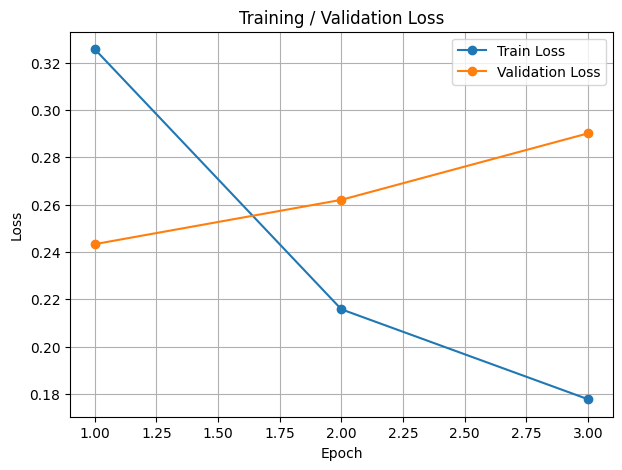

In [22]:
import matplotlib.pyplot as plt

epochs = range(
    1,
    len(history["train_loss"]) + 1
)

plt.figure(figsize=(7, 5))

plt.plot(
    epochs,
    history["train_loss"],
    marker="o",
    label="Train Loss"
)

plt.plot(
    epochs,
    history["val_loss"],
    marker="o",
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training / Validation Loss")

plt.legend()
plt.grid()

plt.show()

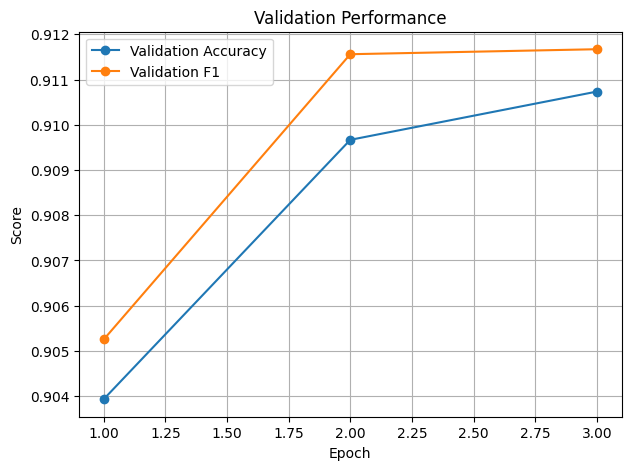

In [23]:
plt.figure(figsize=(7, 5))

plt.plot(
    epochs,
    history["val_accuracy"],
    marker="o",
    label="Validation Accuracy"
)

plt.plot(
    epochs,
    history["val_f1"],
    marker="o",
    label="Validation F1"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Performance")

plt.legend()
plt.grid()

plt.show()

In [24]:
model = AutoModelForSequenceClassification.from_pretrained(
    "./best_koelectra_sentiment"
)

model = model.to(DEVICE)

model.eval()

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

ElectraForSequenceClassification(
  (electra): ElectraModel(
    (embeddings): ElectraEmbeddings(
      (word_embeddings): Embedding(35000, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): ElectraEncoder(
      (layer): ModuleList(
        (0-11): 12 x ElectraLayer(
          (attention): ElectraAttention(
            (self): ElectraSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): ElectraSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): L

In [25]:
test_loss, test_metrics, test_labels, test_predictions = evaluate(
    model,
    test_loader
)

print()
print("========== Test Result ==========")

print(
    f"Test Loss : "
    f"{test_loss:.4f}"
)

print(
    f"Accuracy  : "
    f"{test_metrics['accuracy']:.4f}"
)

print(
    f"Precision : "
    f"{test_metrics['precision']:.4f}"
)

print(
    f"Recall    : "
    f"{test_metrics['recall']:.4f}"
)

print(
    f"F1 Score  : "
    f"{test_metrics['f1']:.4f}"
)

Evaluation:   0%|          | 0/3125 [00:00<?, ?it/s]


========== Test Result ==========
Test Loss : 0.2969
Accuracy  : 0.9094
Precision : 0.9072
Recall    : 0.9134
F1 Score  : 0.9103


In [26]:
print(
    classification_report(
        test_labels,
        test_predictions,
        target_names=[
            "Negative",
            "Positive"
        ],
        digits=4
    )
)

              precision    recall  f1-score   support

    Negative     0.9116    0.9053    0.9084     24826
    Positive     0.9072    0.9134    0.9103     25171

    accuracy                         0.9094     49997
   macro avg     0.9094    0.9093    0.9094     49997
weighted avg     0.9094    0.9094    0.9094     49997



In [27]:
def predict_sentiment(text):

    model.eval()

    inputs = tokenizer(
        text,
        return_tensors="pt",
        truncation=True,
        max_length=MAX_LENGTH
    )

    inputs = {
        key: value.to(DEVICE)
        for key, value in inputs.items()
    }

    with torch.no_grad():

        outputs = model(**inputs)

        probabilities = torch.softmax(
            outputs.logits,
            dim=-1
        )

    predicted_class = torch.argmax(
        probabilities,
        dim=-1
    ).item()

    negative_prob = (
        probabilities[0][0].item()
    )

    positive_prob = (
        probabilities[0][1].item()
    )

    if predicted_class == 1:
        result = "긍정"
    else:
        result = "부정"

    print(f"리뷰 : {text}")
    print(f"예측 : {result}")

    print(
        f"부정 확률 : "
        f"{negative_prob * 100:.2f}%"
    )

    print(
        f"긍정 확률 : "
        f"{positive_prob * 100:.2f}%"
    )

In [28]:
predict_sentiment(
    "배우들의 연기가 정말 좋았고 영화도 재미있었다."
)

리뷰 : 배우들의 연기가 정말 좋았고 영화도 재미있었다.
예측 : 긍정
부정 확률 : 0.17%
긍정 확률 : 99.83%


In [29]:
predict_sentiment(
    "스토리도 엉망이고 너무 지루해서 시간이 아까웠다."
)

리뷰 : 스토리도 엉망이고 너무 지루해서 시간이 아까웠다.
예측 : 부정
부정 확률 : 99.88%
긍정 확률 : 0.12%


In [30]:
predict_sentiment(
    "배우 연기는 좋았지만 스토리는 너무 지루했다."
)

리뷰 : 배우 연기는 좋았지만 스토리는 너무 지루했다.
예측 : 부정
부정 확률 : 99.86%
긍정 확률 : 0.14%


In [31]:
predict_sentiment(
    "와 정말 재미있어서 보는 내내 잠이 오더라."
)

리뷰 : 와 정말 재미있어서 보는 내내 잠이 오더라.
예측 : 부정
부정 확률 : 99.85%
긍정 확률 : 0.15%


# 실습 결과 보고서 - KoELECTRA V2

### Parameters

기존 실험과 비교하여 Learning Rate를 낮추고 Weight Decay를 추가하였으며, 학습 Epoch와 평가 데이터 구성도 조정하였다.

| 설정 | V2 |
|---|---:|
| Max Length | 128 |
| Batch Size | 16 |
| Epoch | 3 |
| Learning Rate | 1e-5 |
| Weight Decay | 0.01 |
| Train Data | 134,995 |
| Validation Data | 15,000 |
| Test Data | 49,997 |

---

## 학습 결과

Epoch별 Validation 성능은 다음과 같다.

| Epoch | Train Loss | Val Loss | Accuracy | F1-score |
|---:|---:|---:|---:|---:|
| 1 | 0.3257 | 0.2433 | 0.9039 | 0.9053 |
| 2 | 0.2158 | 0.2620 | 0.9097 | 0.9116 |
| 3 | 0.1778 | 0.2901 | 0.9107 | 0.9117 |

Train Loss는 계속 감소하였고 Validation Accuracy와 F1-score 역시 전체적으로 향상되었다.

다만 Epoch가 증가하면서 Validation Loss가 함께 증가했기 때문에 **일부 과적합 현상도 확인할 수 있었다.**

---

## 최종 Test 성능

최종 Test 데이터에 대한 평가 결과는 다음과 같다.

| 평가 지표 | 기존 실험 | V2 |
|---|---:|---:|
| Test Loss | 0.3765 | **0.2969** |
| Accuracy | 0.8812 | **0.9094** |
| Precision | 0.8631 | **0.9072** |
| Recall | 0.9083 | **0.9134** |
| F1-score | 0.8852 | **0.9103** |

기존 모델과 비교했을 때 Accuracy는 약 **2.82%p**, F1-score는 약 **2.51%p** 향상되었다.

특히 Precision이 0.8631에서 0.9072로 증가하면서 긍정으로 예측한 결과의 정확성이 크게 향상된 것을 확인하였다.

---

## 결과 분석

기존 실험보다 Learning Rate를 낮추고 Weight Decay를 추가한 결과 전체적인 Test 성능이 향상되었다.

특히 Accuracy와 F1-score가 모두 0.91 수준까지 증가하여 모델이 영화 리뷰의 감정을 비교적 안정적으로 분류하는 것을 확인하였다.

하지만 과적합 현상은 그대로 나타났다. (Early Stopping을 적용하는게 나을것 같다.)

---